--- Data Info & Missing Values ---
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   person_age           32581 non-null  int64  
 1   person_income        32581 non-null  int64  
 2   person_emp_length    32581 non-null  int64  
 3   loan_intent          32581 non-null  str    
 4   loan_grade           32581 non-null  str    
 5   loan_amnt            32581 non-null  int64  
 6   loan_int_rate        32581 non-null  float64
 7   loan_status          32581 non-null  int64  
 8   loan_percent_income  32581 non-null  float64
dtypes: float64(2), int64(5), str(2)
memory usage: 2.2 MB
None

Missing Values Count:
person_age             0
person_income          0
person_emp_length      0
loan_intent            0
loan_grade             0
loan_amnt              0
loan_int_rate          0
loan_status            0
loan_percent_income    0
dtype: 

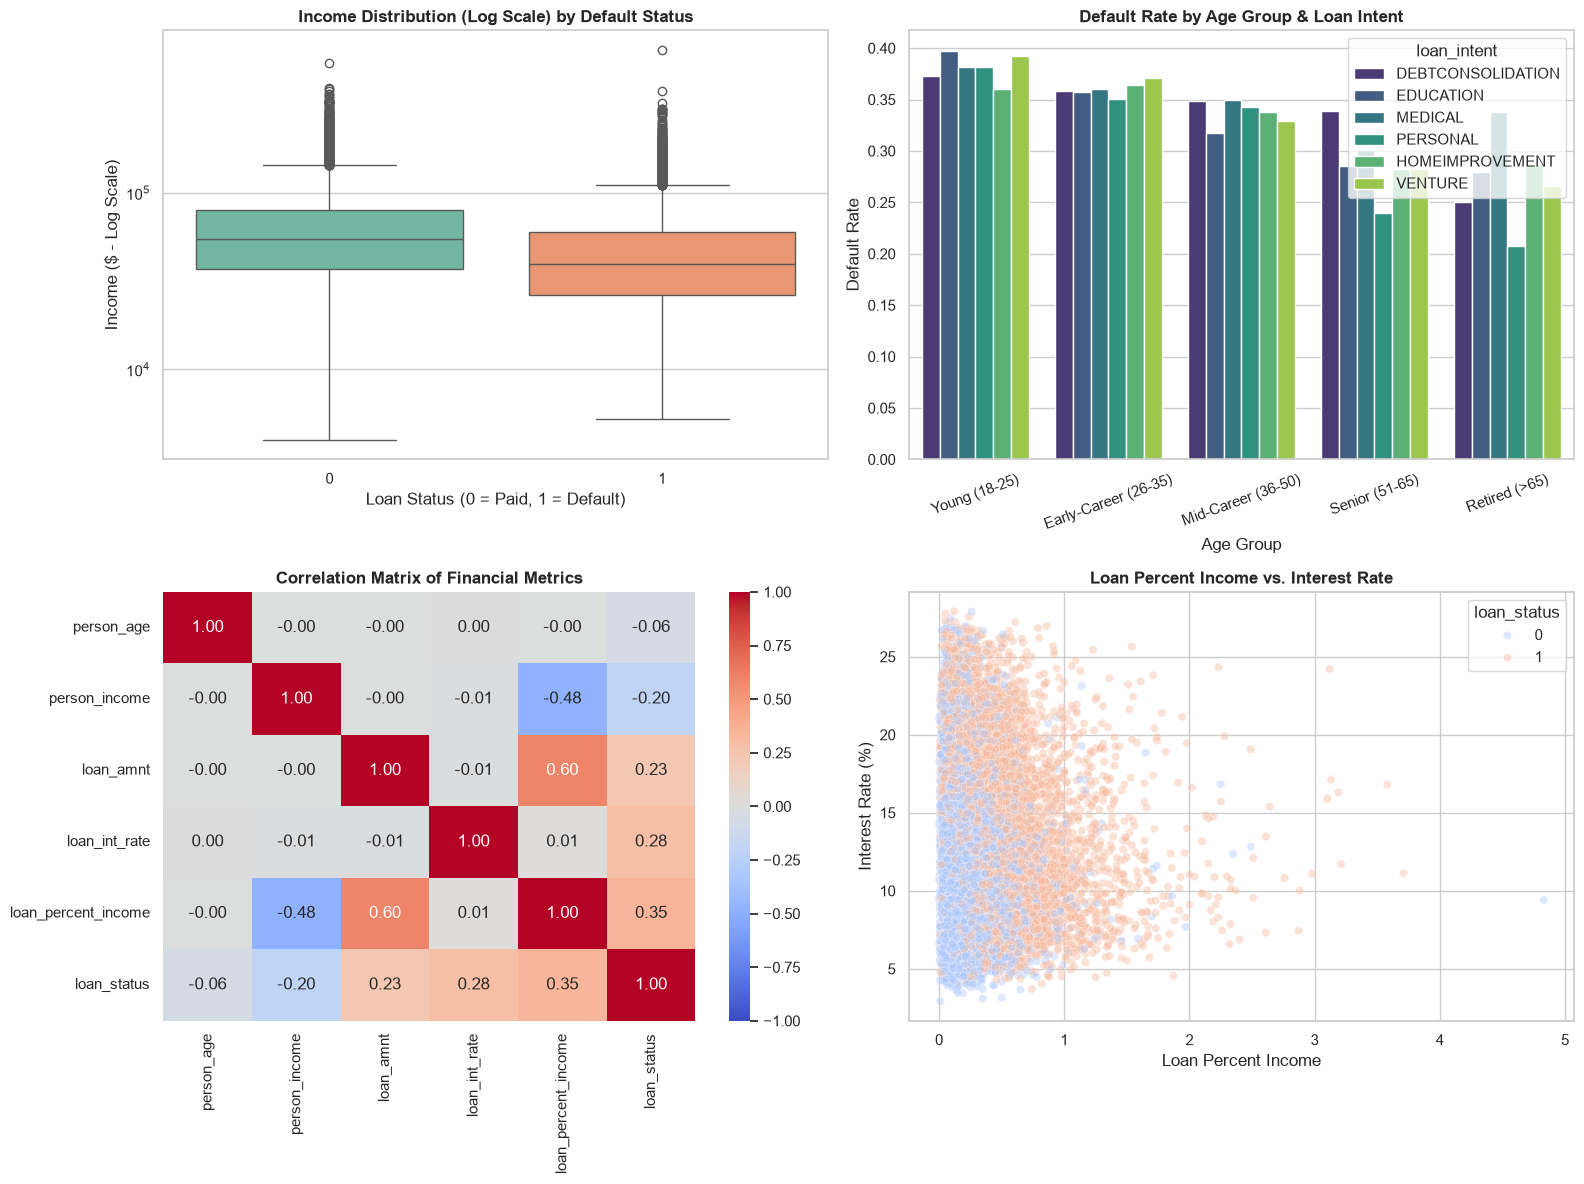

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_credit = pd.read_csv('credit_risk_dataset.csv')

print("--- Data Info & Missing Values ---")
print(df_credit.info())
print("\nMissing Values Count:")
print(df_credit.isnull().sum())

print("\n--- Descriptive Statistics ---")
print(df_credit.describe().round(2))

df_credit['loan_int_rate'] = df_credit.groupby('loan_grade')['loan_int_rate'].transform(
    lambda x: x.fillna(x.median())
)

df_credit['person_emp_length'] = df_credit['person_emp_length'].fillna(df_credit['person_emp_length'].median())


df_credit = df_credit[df_credit['person_age'] <= 80].copy()

print("Missing values after imputation:", df_credit.isnull().sum().sum())


df_credit['loan_to_income_ratio'] = df_credit['loan_amnt'] / (df_credit['person_income'] + 1)


df_credit['income_per_emp_year'] = df_credit['person_income'] / (df_credit['person_emp_length'] + 1)


df_credit['age_group'] = pd.cut(
    df_credit['person_age'], 
    bins=[18, 25, 35, 50, 65, 100], 
    labels=['Young (18-25)', 'Early-Career (26-35)', 'Mid-Career (36-50)', 'Senior (51-65)', 'Retired (>65)']
)

df_credit[['loan_to_income_ratio', 'income_per_emp_year', 'age_group']].head()

multi_pivot = df_credit.pivot_table(
    index=['loan_intent', 'age_group'], 
    columns='loan_grade', 
    values=['loan_status', 'loan_to_income_ratio'], 
    aggfunc={'loan_status': 'mean', 'loan_to_income_ratio': 'mean'}
)

print("--- Multi-dimensional Pivot Table (Default Rates %) ---")
print((multi_pivot['loan_status'] * 100).round(2))



sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))


sns.boxplot(ax=axes[0, 0], data=df_credit, x='loan_status', y='person_income', hue='loan_status', palette='Set2', legend=False)
axes[0, 0].set_yscale('log')
axes[0, 0].set_title('Income Distribution (Log Scale) by Default Status', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Loan Status (0 = Paid, 1 = Default)')
axes[0, 0].set_ylabel('Income ($ - Log Scale)')


sns.barplot(ax=axes[0, 1], data=df_credit, x='age_group', y='loan_status', hue='loan_intent', palette='viridis', errorbar=None)
axes[0, 1].set_title('Default Rate by Age Group & Loan Intent', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Age Group')
axes[0, 1].set_ylabel('Default Rate')
axes[0, 1].tick_params(axis='x', rotation=20)


numeric_cols = ['person_age', 'person_income', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'loan_status']
corr_matrix = df_credit[numeric_cols].corr()
sns.heatmap(ax=axes[1, 0], data=corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
axes[1, 0].set_title('Correlation Matrix of Financial Metrics', fontsize=12, fontweight='bold')


sns.scatterplot(ax=axes[1, 1], data=df_credit, x='loan_percent_income', y='loan_int_rate', hue='loan_status', alpha=0.4, palette='coolwarm')
axes[1, 1].set_title('Loan Percent Income vs. Interest Rate', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Loan Percent Income')
axes[1, 1].set_ylabel('Interest Rate (%)')

plt.tight_layout()
plt.show()